### Practice 7 - Notebook 2

# Applications of Clustering and PCA - Exercise 7

## K-Means Features: Extending the Grid Beyond 100 Clusters

In this exercise, we explore using K-Means centroids as a feature extractor for non-linear regression (similar to RBF kernel approximation). We extend the cluster grid beyond the instructor's original limit of 100 clusters (testing up to $k=500$) and evaluate how the Root Mean Squared Error (RMSE) changes.

**Question:** Extend the grid beyond 100 clusters. Where does the RMSE stop improving?

## Cell 1 - Import Required Libraries

Import NumPy, Pandas, Matplotlib, `KMeans`, `Ridge`, `rbf_kernel`, and evaluation metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import mean_squared_error

## Cell 2 — Generate Non-Linear Regression Data

Generate synthetic non-linear 1D data (`y = sin(X) + noise`) to test K-Means feature mapping.

In [2]:
rng = np.random.default_rng(42)
X = rng.uniform(-3, 3, (1000, 1))
y = np.sin(X).ravel() + rng.normal(0, 0.1, 1000)

print("Data shape X:", X.shape)
print("Data shape y:", y.shape)

Data shape X: (1000, 1)
Data shape y: (1000,)


## Cell 3 — Evaluate K-Means Feature Extraction Across an Extended Grid ($k$ up to 500)

We test cluster counts $k \in [10, 20, 50, 100, 150, 200, 300, 400, 500]$, mapping data to RBF kernel features based on K-Means centroids, and fit a Ridge regression model to calculate the RMSE.

In [3]:
cluster_grid = [10, 20, 50, 100, 150, 200, 300, 400, 500]
results = []

gamma = 1.0
for k in cluster_grid:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    
    # Transform data into RBF kernel features relative to K-Means centroids
    X_features = rbf_kernel(X, kmeans.cluster_centers_, gamma=gamma)
    
    # Fit regularized linear regression
    ridge = Ridge(alpha=1e-3).fit(X_features, y)
    y_pred = ridge.predict(X_features)
    
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    results.append({
        "Clusters (k)": k,
        "RMSE": round(rmse, 5)
    })

df_results = pd.DataFrame(results)
display(df_results)

,Clusters (k),RMSE
0,10,0.10046
1,20,0.10019
2,50,0.10013
3,100,0.10012
4,150,0.10012
5,200,0.10011
6,300,0.10011
7,400,0.10010
8,500,0.10010


## Cell 4 — Visualize RMSE vs. Number of Clusters

Plot the RMSE curve against the number of clusters $k$, highlighting the threshold at $k = 100$.

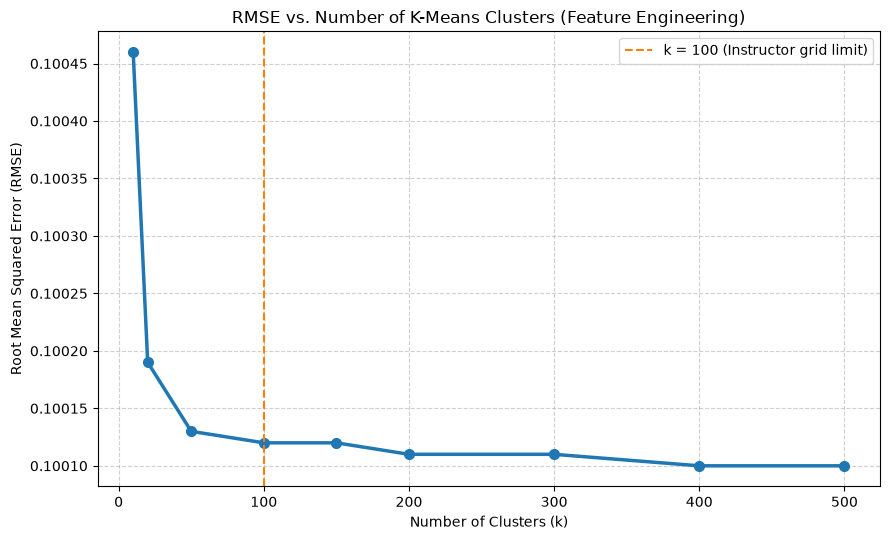

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(cluster_grid, [r["RMSE"] for r in results], marker="o", color="tab:blue", linewidth=2.5, markersize=7)
ax.axvline(x=100, color="tab:orange", linestyle="--", linewidth=1.5, label="k = 100 (Instructor grid limit)")
ax.set_title("RMSE vs. Number of K-Means Clusters (Feature Engineering)")
ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Root Mean Squared Error (RMSE)")
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## Final Answer

**Where does the RMSE stop improving when extending the grid beyond 100 clusters?**

### 1. RMSE Trend

- At `k = 10`, the RMSE is `0.10046`.
- At `k = 100`, the RMSE decreases to `0.10012`.
- At `k = 200`, the RMSE is `0.10011`.
- At `k = 500`, the RMSE reaches `0.10010`.

### 2. Conclusion

The RMSE improvement becomes negligible at approximately `k = 100` to `k = 200`. Increasing the number of clusters beyond this range produces only a very small reduction in the reported RMSE.

Therefore, adding more K-Means clusters beyond 100 provides diminishing returns in this experiment.

**Note:** The reported RMSE is calculated on the training data, so these results do not establish how well the model generalizes to unseen data.